# Assignment 2: Diabetes Classification
**IE500618 Machine Learning**

Jørund Sæten Birkeland, Matteo Castelli, Haakon Torvik Gullbekk, and Marius Alexander Langaas Klæbo

We examine whether 21 survey features can help distinguish **no diabetes (0)** from
**prediabetes or diabetes (1)**. The purpose is to understand a classification workflow,
interpret its errors, and compare two decision thresholds. It is not a clinical diagnosis.

The notebook follows the assignment and the supplied dataset guide. The heart-disease
lecture notebook provides the preprocessing pattern. Detailed EDA uses TRAIN: we split
after checking the file structure and target distribution, before exploring relationships.
This small change in presentation keeps TEST out of development decisions.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)
from sklearn.exceptions import ConvergenceWarning
import sklearn

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
DATA_PATH = Path('diabetes_binary_classification_data.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Put the supplied CSV beside this notebook.')
RESULTS = Path('results')
FIGURES = Path('figures')
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

def show_figure(fig, filename):
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

versions = {'Python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
            'scikit-learn': sklearn.__version__}
display(pd.Series(versions, name='Version').to_frame())

,Version
Python,3.12.14
numpy,2.5.4
pandas,3.0.1
matplotlib,3.11.2
scikit-learn,1.9.1


## 1. Understand and check the data

**Question:** What does one row describe, what is the target, and are both classes represented?

One row represents a survey respondent. According to the supplied guide, the data use
health-related BRFSS survey variables. `Diabetes_binary` is y; the remaining 21 columns are X.
Class 1 combines prediabetes and diabetes, so we cannot separate those conditions here.
We verify the guide's expected shape, missingness, and counts against the actual CSV.

In [2]:
df = pd.read_csv(DATA_PATH)
target = 'Diabetes_binary'
assert df.shape == (253680, 22), f'Unexpected shape: {df.shape}'
assert df.columns.is_unique
assert not df.isna().any().any(), 'Investigate unexpected missing values.'
assert set(df[target].unique()) == {0, 1}
assert np.equal(df.to_numpy(), np.floor(df.to_numpy())).all()
# Values happen to be whole numbers; their meanings still determine their types.
df = df.astype(int)
class_counts = df[target].value_counts().sort_index()
assert class_counts.to_dict() == {0: 218334, 1: 35346}
class_table = pd.DataFrame({'Count': class_counts,
                            'Percent': 100 * class_counts / len(df)})
class_table.index.name = 'Class'
class_table.to_csv(RESULTS / 'class_distribution.csv')
print('Shape:', df.shape)
print('Missing cells:', int(df.isna().sum().sum()))
print('Rows identical to an earlier row:', int(df.duplicated().sum()))
print('Identical rows are retained, as instructed by the dataset guide.')
display(df.head())
display(class_table.round(2))
display(df.agg(['min', 'max']).T.rename(columns={'min': 'Minimum', 'max': 'Maximum'}))

Shape: (253680, 22)
Missing cells: 0
Rows identical to an earlier row: 24206
Identical rows are retained, as instructed by the dataset guide.


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,...,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,...,15,1,0,9,4,3
1,0,0,0,0,25,1,...,0,0,0,7,6,1
2,0,1,1,1,28,0,...,30,1,0,9,4,8
3,0,1,0,1,27,0,...,0,0,0,11,3,6
4,0,1,1,1,24,0,...,0,0,0,11,5,4


,Count,Percent
Class,,
0,218334,86.07
1,35346,13.93


,Minimum,Maximum
Diabetes_binary,0,1
HighBP,0,1
HighChol,0,1
CholCheck,0,1
BMI,12,98
Smoker,0,1
Stroke,0,1
HeartDiseaseorAttack,0,1
PhysActivity,0,1
Fruits,0,1


In [3]:
numerical_features = ['BMI', 'MentHlth', 'PhysHlth']
ordinal_features = ['GenHlth', 'Age', 'Education', 'Income']
binary_features = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke',
                   'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
                   'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
ordinal_labels = {
    'GenHlth': ['Excellent', 'Very good', 'Good', 'Fair', 'Poor'],
    'Age': ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54',
            '55-59', '60-64', '65-69', '70-74', '75-79', '80+'],
    'Education': ['No school / kindergarten', 'Grades 1-8', 'Grades 9-11',
                  'High school', 'Some college / technical', 'College / technical graduate'],
    'Income': ['< $10k', '$10k-<15k', '$15k-<20k', '$20k-<25k', '$25k-<35k',
               '$35k-<50k', '$50k-<75k', '$75k+']}
meanings = {
    'BMI': 'Body Mass Index', 'MentHlth': 'Days of poor mental health in past 30 days',
    'PhysHlth': 'Days of poor physical health in past 30 days',
    'GenHlth': 'Self-rated general health, excellent to poor', 'Age': 'Age group, not years',
    'Education': 'Highest education category', 'Income': 'Household income band',
    'HighBP': 'High blood pressure', 'HighChol': 'High cholesterol',
    'CholCheck': 'Cholesterol checked within past five years',
    'Smoker': 'Smoked at least 100 cigarettes in lifetime', 'Stroke': 'Ever told of a stroke',
    'HeartDiseaseorAttack': 'Coronary heart disease or myocardial infarction',
    'PhysActivity': 'Physical activity in past 30 days, excluding work',
    'Fruits': 'Fruit consumed at least once per day', 'Veggies': 'Vegetables at least once per day',
    'HvyAlcoholConsump': 'Heavy alcohol consumption under the dataset definition',
    'AnyHealthcare': 'Any healthcare coverage', 'NoDocbcCost': 'Unable to see doctor because of cost',
    'DiffWalk': 'Serious difficulty walking or climbing stairs', 'Sex': 'Recorded sex'}
all_features = numerical_features + ordinal_features + binary_features
assert len(all_features) == 21 and set(all_features) == set(df.columns) - {target}
for feature in binary_features:
    assert set(df[feature].unique()) <= {0, 1}
for feature in ordinal_features:
    assert set(df[feature].unique()) <= set(range(1, len(ordinal_labels[feature]) + 1))
assert df['BMI'].between(12, 98).all()
assert df[['MentHlth', 'PhysHlth']].apply(lambda s: s.between(0, 30).all()).all()
feature_guide = pd.DataFrame([
    {'Feature': feature, 'Meaning': meanings[feature],
     'Type': 'Numerical' if feature in numerical_features else
             'Ordered category' if feature in ordinal_features else 'Binary category',
     'Representation': 'StandardScaler' if feature in numerical_features else
                       'Explicit OrdinalEncoder' if feature in ordinal_features else 'Keep 0/1'}
    for feature in df.columns if feature != target])
feature_guide.to_csv(RESULTS / 'feature_guide.csv', index=False)
display(feature_guide)

,Feature,Meaning,Type,Representation
0,HighBP,High blood pressure,Binary category,Keep 0/1
1,HighChol,High cholesterol,Binary category,Keep 0/1
2,CholCheck,Cholesterol checked within past five years,Binary category,Keep 0/1
3,BMI,Body Mass Index,Numerical,StandardScaler
4,Smoker,Smoked at least 100 cigarettes in lifetime,Binary category,Keep 0/1
5,Stroke,Ever told of a stroke,Binary category,Keep 0/1
6,HeartDiseaseorAttack,Coronary heart disease or myocardial infarction,Binary category,Keep 0/1
7,PhysActivity,"Physical activity in past 30 days, excluding work",Binary category,Keep 0/1
8,Fruits,Fruit consumed at least once per day,Binary category,Keep 0/1
9,Veggies,Vegetables at least once per day,Binary category,Keep 0/1


### Three examples of meaning before representation

- **BMI = 30:** a numerical BMI measurement. Its value describes an amount.
- **HighBP = 1:** the respondent has high blood pressure. This is a yes/no category.
- **Age = 9:** the respondent is in the 60-64 age group. It does not mean nine years old.

All columns were stored as numbers, but treating them all as measured quantities would
misread the categories. `MentHlth` and `PhysHlth` are genuine counts of days. `Sex` uses
0 = female and 1 = male; other binary predictors use the guide's no/yes coding.
The heavy-alcohol indicator follows the supplied definition: at least 14 drinks/week
for adult men or seven for adult women. We do not reinterpret it as current health advice.

The positive class is uncommon. A prediction of class 0 for everyone would get about
86% of rows right while finding none of class 1. Accuracy therefore needs to be read
alongside recall, precision, F1, and the confusion matrix.

## 2. Create TRAIN and TEST before detailed EDA

**Question:** How do we retain both classes while protecting the final evaluation?

We make one reproducible 80/20 split with `stratify=y`. Stratification preserves the
original class proportions approximately; it does not produce equal class sizes.
We inspect split counts for verification only. All detailed feature EDA below uses TRAIN.
TEST is not balanced, resampled, used to select features, or used to tune the model.

In [4]:
X = df.drop(columns=target)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
split_table = pd.DataFrame({
    'Rows': [len(y_train), len(y_test)],
    'Class 0': [(y_train == 0).sum(), (y_test == 0).sum()],
    'Class 1': [(y_train == 1).sum(), (y_test == 1).sum()],
    'Class 1 percent': [100 * y_train.mean(), 100 * y_test.mean()]}, index=['TRAIN', 'TEST'])
split_table.to_csv(RESULTS / 'split_distribution.csv')
display(split_table.round(3))
train_eda = X_train.copy()
train_eda[target] = y_train

,Rows,Class 0,Class 1,Class 1 percent
TRAIN,202944,174667,28277,13.933
TEST,50736,43667,7069,13.933


## 3. Explore every input feature using TRAIN

### 3.1 Numerical features

**Question:** How do BMI and the two counts of poor-health days differ between classes?

Each figure shows the overall TRAIN distribution, distributions normalised within each
class, and a boxplot by class. Density histograms allow shape comparisons despite unequal
class sizes. Both classes use the same bin edges. The summary table reports means,
medians, quartiles, and the proportion at zero. Unusual observations are retained:
an extreme recorded value is not by itself evidence of an error.

Class 0   Class 1
BMI      count   174667.00  28277.00
         mean        27.80     31.97
         median      27.00     31.00
         std          6.27      7.37
         min         12.00     13.00
         max         98.00     98.00
MentHlth count   174667.00  28277.00
         mean         2.98      4.48
         median       0.00      0.00
         std          7.11      8.96
         min          0.00      0.00
         max         30.00     30.00
PhysHlth count   174667.00  28277.00
         mean         3.65      7.98
         median       0.00      1.00
         std          8.07     11.30
         min          0.00      0.00
         max         30.00     30.00

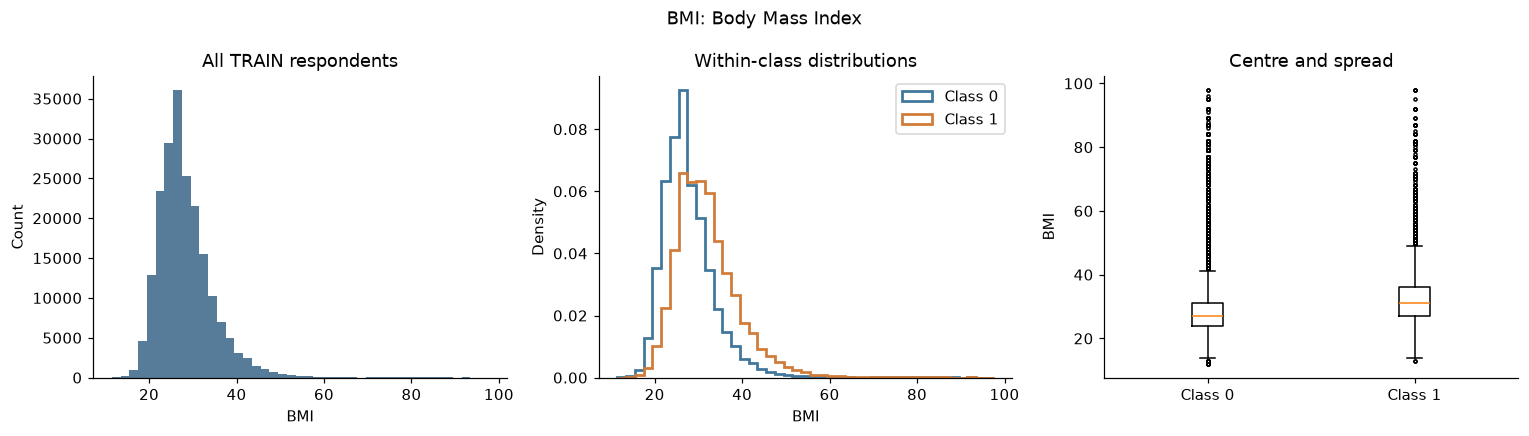

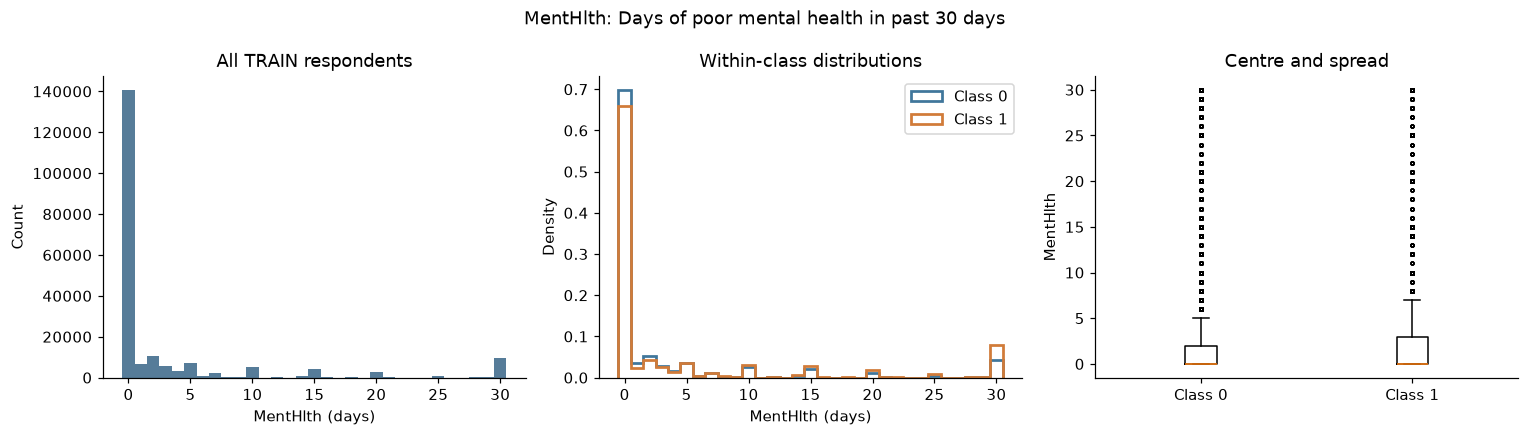

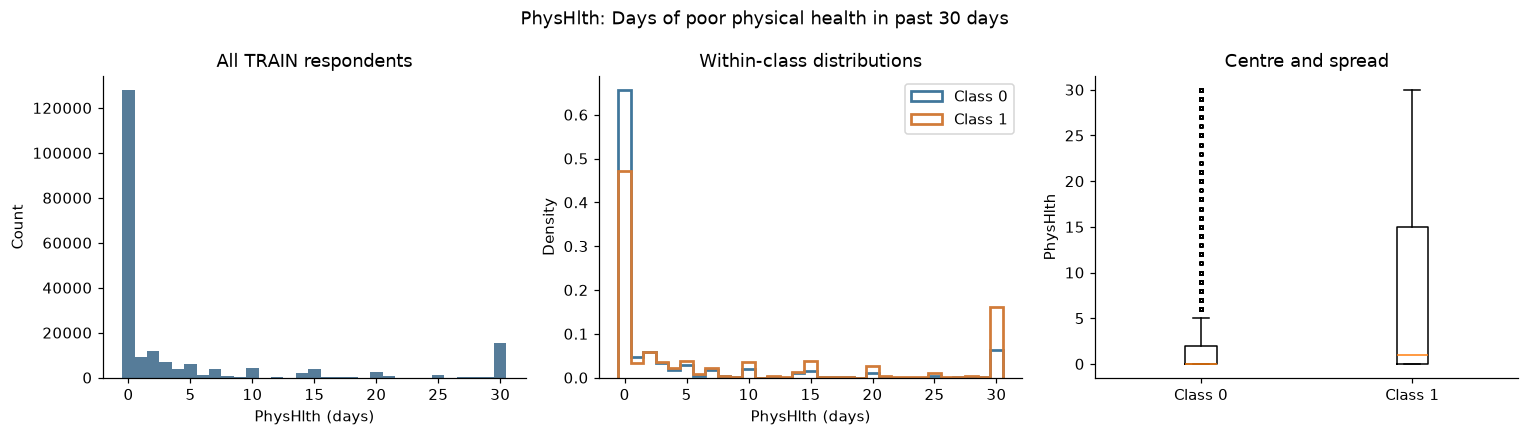

,Feature,Class,Mean,Median,Q1,Q3,Zero percent
0,BMI,0,27.80,27.0,24.0,31.0,0.00
1,BMI,1,31.97,31.0,27.0,36.0,0.00
2,MentHlth,0,2.98,0.0,0.0,2.0,69.72
3,MentHlth,1,4.48,0.0,0.0,3.0,66.05
4,PhysHlth,0,3.65,0.0,0.0,2.0,65.54
5,PhysHlth,1,7.98,1.0,0.0,15.0,47.08


In [5]:
numerical_summary = train_eda.groupby(target)[numerical_features].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']).T
numerical_summary.columns = ['Class 0', 'Class 1']
numerical_summary.to_csv(RESULTS / 'numerical_summary.csv')
display(numerical_summary.round(2))
detail_rows = []
for feature in numerical_features:
    for cls in [0, 1]:
        values = train_eda.loc[train_eda[target] == cls, feature]
        detail_rows.append({'Feature': feature, 'Class': cls, 'Mean': values.mean(),
                            'Median': values.median(), 'Q1': values.quantile(.25),
                            'Q3': values.quantile(.75), 'Zero percent': 100 * values.eq(0).mean()})
    bins = np.arange(11.5, 99.5, 2) if feature == 'BMI' else np.arange(-.5, 31.5, 1)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].hist(train_eda[feature], bins=bins, color='#567c99')
    axes[0].set(title='All TRAIN respondents', ylabel='Count')
    groups = [train_eda.loc[train_eda[target] == cls, feature] for cls in [0, 1]]
    for cls, values, colour in zip([0, 1], groups, ['#40769b', '#d17b39']):
        axes[1].hist(values, bins=bins, density=True, histtype='step', linewidth=1.8,
                     label=f'Class {cls}', color=colour)
    axes[1].set(title='Within-class distributions', ylabel='Density')
    axes[1].legend()
    axes[2].boxplot(groups, tick_labels=['Class 0', 'Class 1'], flierprops={'markersize': 2})
    axes[2].set(title='Centre and spread', ylabel=feature)
    for ax in axes[:2]: ax.set_xlabel(feature + (' (days)' if feature != 'BMI' else ''))
    fig.suptitle(f'{feature}: {meanings[feature]}', fontsize=12)
    fig.tight_layout()
    show_figure(fig, f'eda_{feature}.png')
numerical_details = pd.DataFrame(detail_rows)
numerical_details.to_csv(RESULTS / 'numerical_details.csv', index=False)
display(numerical_details.round(2))

### 3.2 Binary features

**Question:** Within each 0/1 category, what proportion of respondents are class 1?

The table covers all 14 binary predictors. Counts and category shares describe how common
each category is. Class-1 percentages use the category count as the denominator; they are
not percentages of all class-1 respondents. The figures pair category counts with class-1
percentages. Sex is labelled female/male rather than no/yes.

Count  Class 1 count  Category percent  \
Feature              Code                                            
HighBP               0     115882           6984             57.10   
                     1      87062          21293             42.90   
HighChol             0     116834           9307             57.57   
                     1      86110          18970             42.43   
CholCheck            0       7627            189              3.76   
                     1     195317          28088             96.24   
Smoker               0     113068          13612             55.71   
                     1      89876          14665             44.29   
Stroke               0     194744          25663             95.96   
                     1       8200           2614              4.04   
HeartDiseaseorAttack 0     183817          21957             90.58   
                     1      19127           6320              9.42   
PhysActivity         0      49317          10426             24.30   
                     1     153627          17851             75.70   
Fruits               0      74191          11808             36.56   
                     1     128753          16469             63.44   
Veggies              0      38270           6847             18.86   
                     1     164674          21430             81.14   
HvyAlcoholConsump    0     191634          27620             94.43   
                     1      11310            657              5.57   
AnyHealthcare        0       9914           1140              4.89   
                     1     193030          27137             95.11   
NoDocbcCost          0     185770          25251             91.54   
                     1      17174           3026              8.46   
DiffWalk             0     168817          17744             83.18   
                     1      34127          10533             16.82   
Sex                  0     113443          14726             55.90   
                     1      89501          13551             44.10   

                           Class 1 percent  
Feature              Code                   
HighBP               0                6.03  
                     1               24.46  
HighChol             0                7.97  
                     1               22.03  
CholCheck            0                2.48  
                     1               14.38  
Smoker               0               12.04  
                     1               16.32  
Stroke               0               13.18  
                     1               31.88  
HeartDiseaseorAttack 0               11.95  
                     1               33.04  
PhysActivity         0               21.14  
                     1               11.62  
Fruits               0               15.92  
                     1               12.79  
Veggies              0               17.89  
                     1               13.01  
HvyAlcoholConsump    0               14.41  
                     1                5.81  
AnyHealthcare        0               11.50  
                     1               14.06  
NoDocbcCost          0               13.59  
                     1               17.62  
DiffWalk             0               10.51  
                     1               30.86  
Sex                  0               12.98  
                     1               15.14

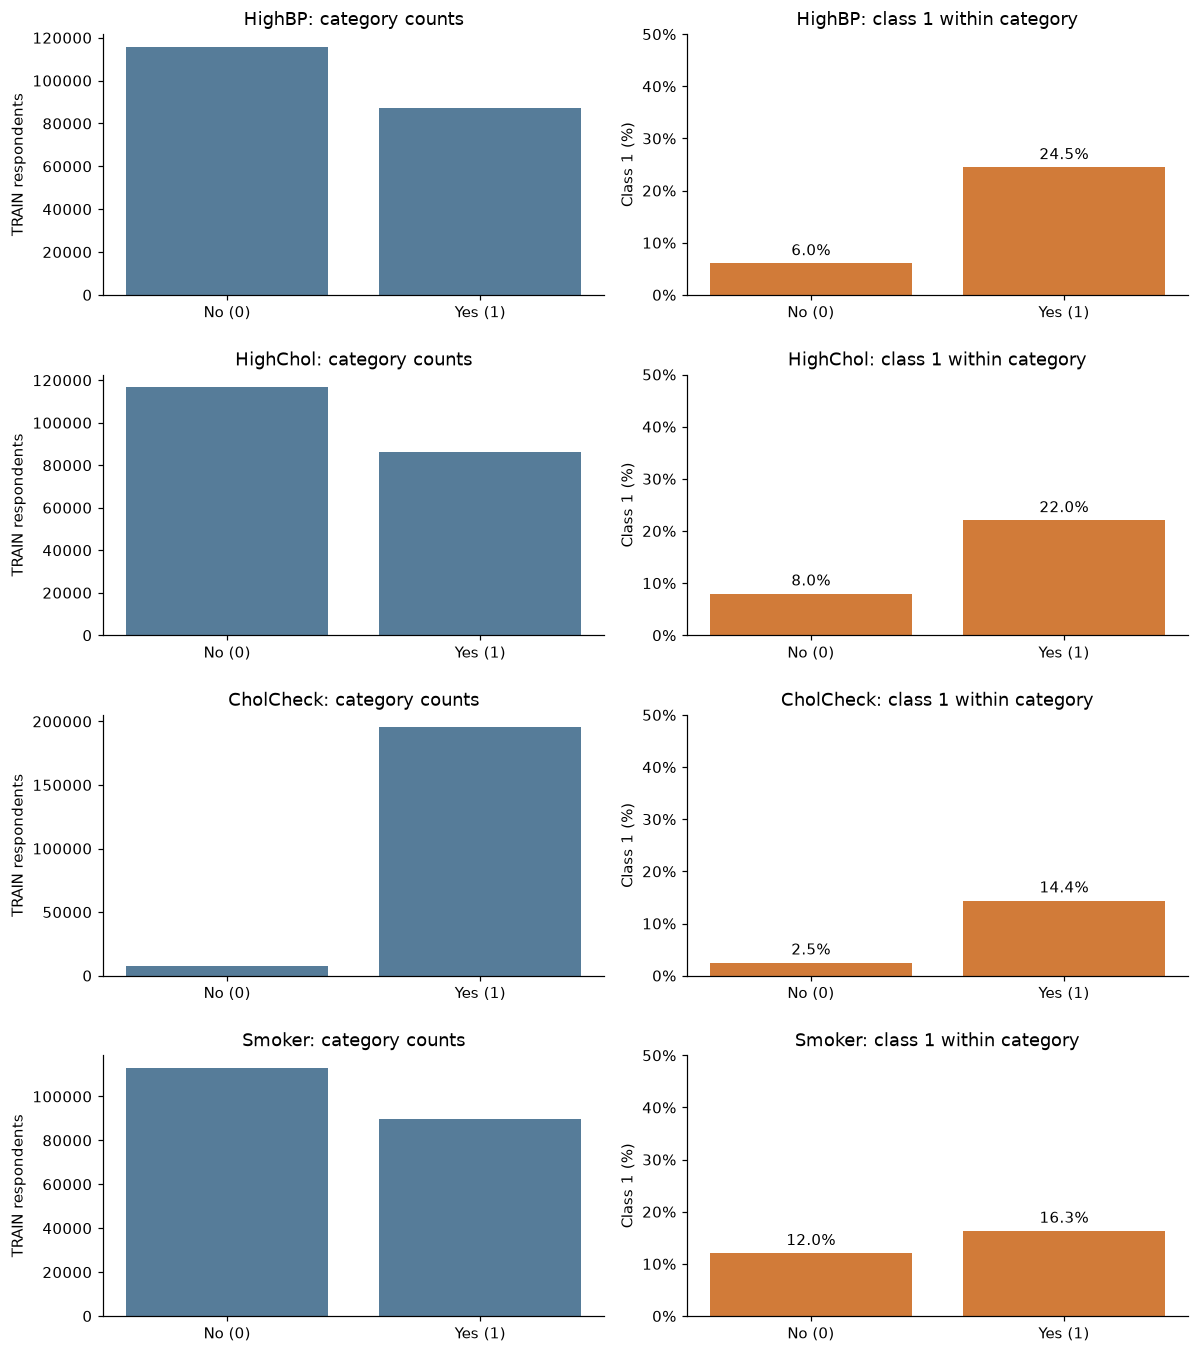

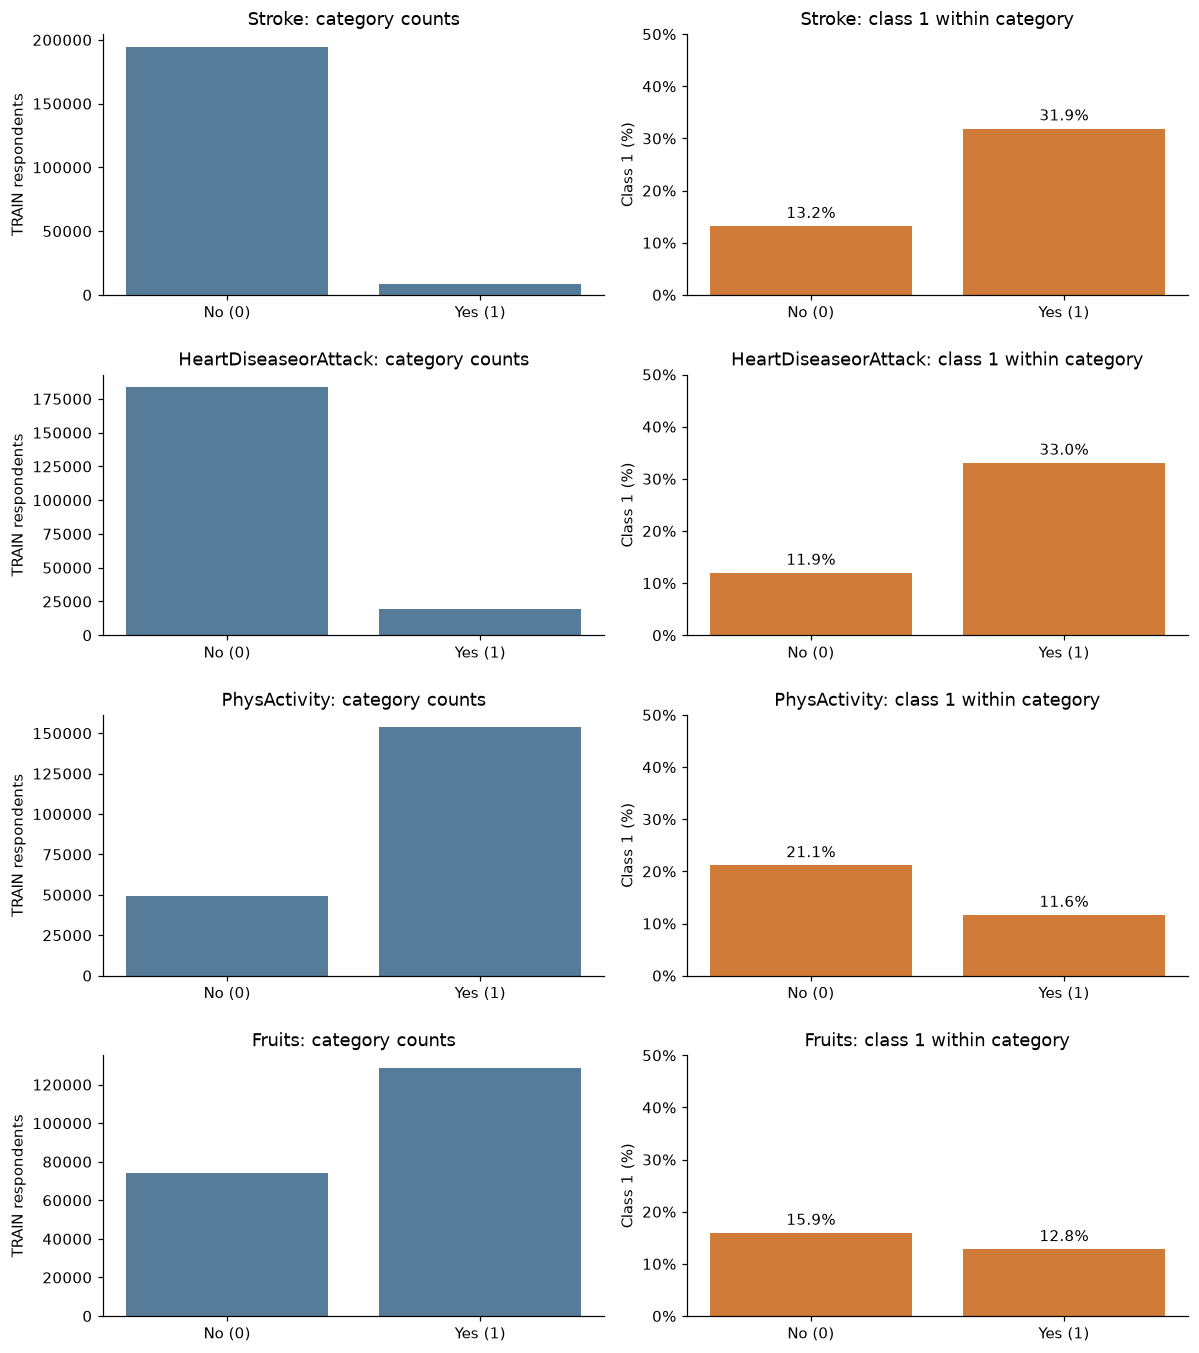

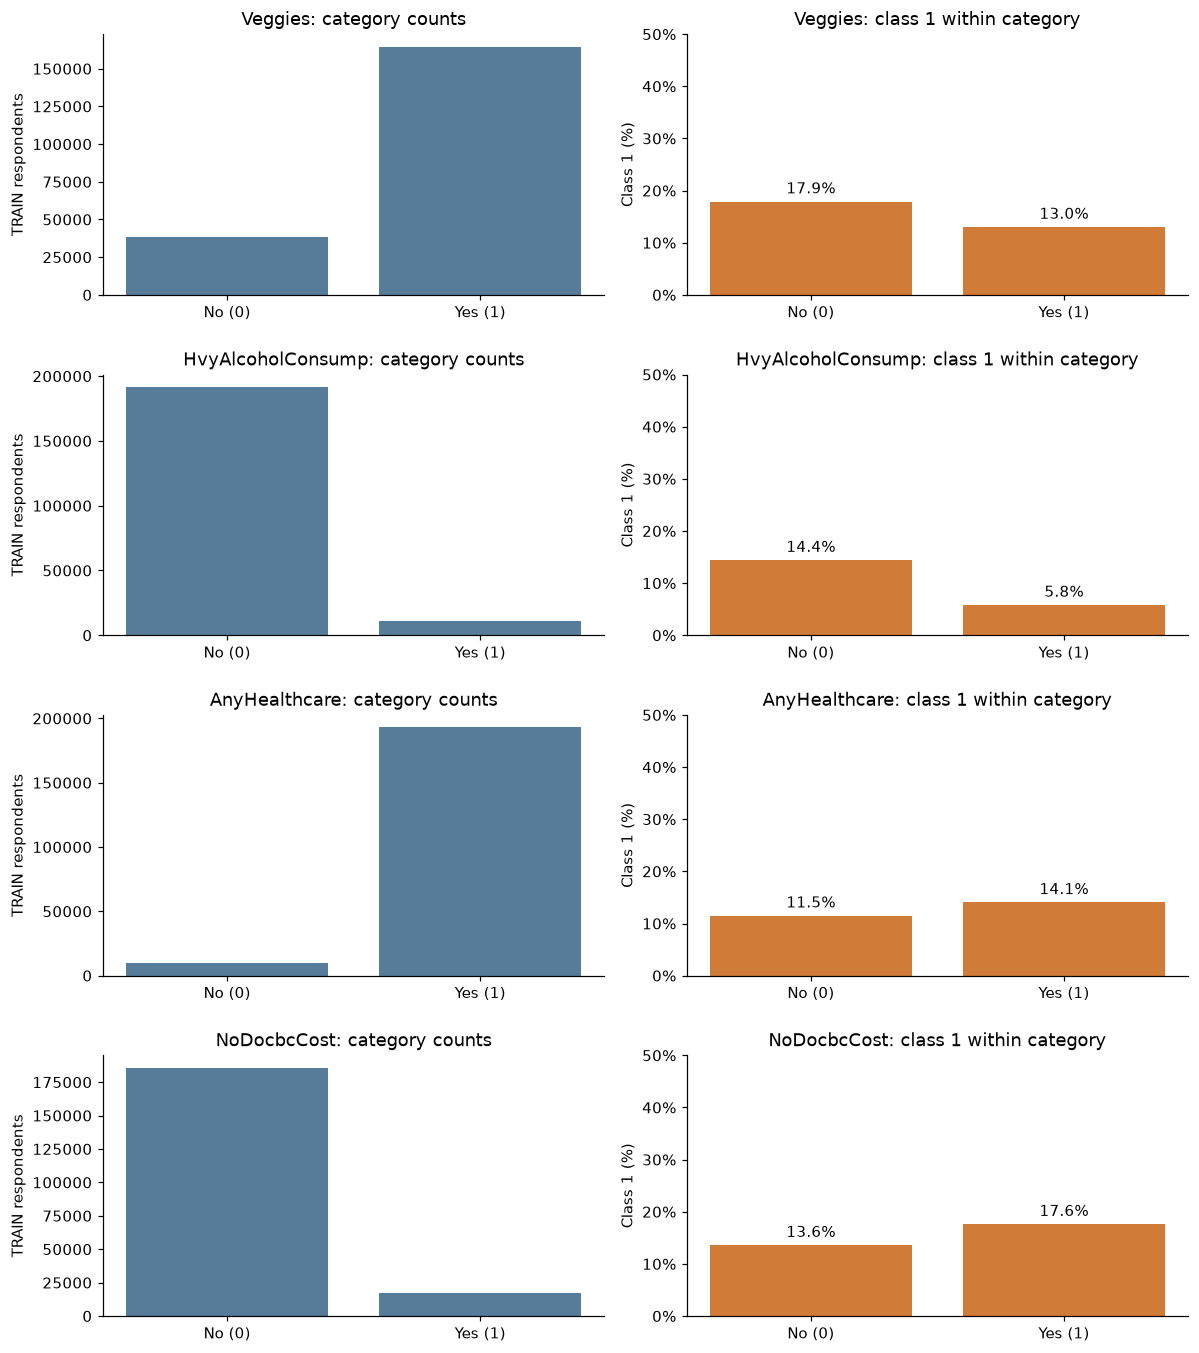

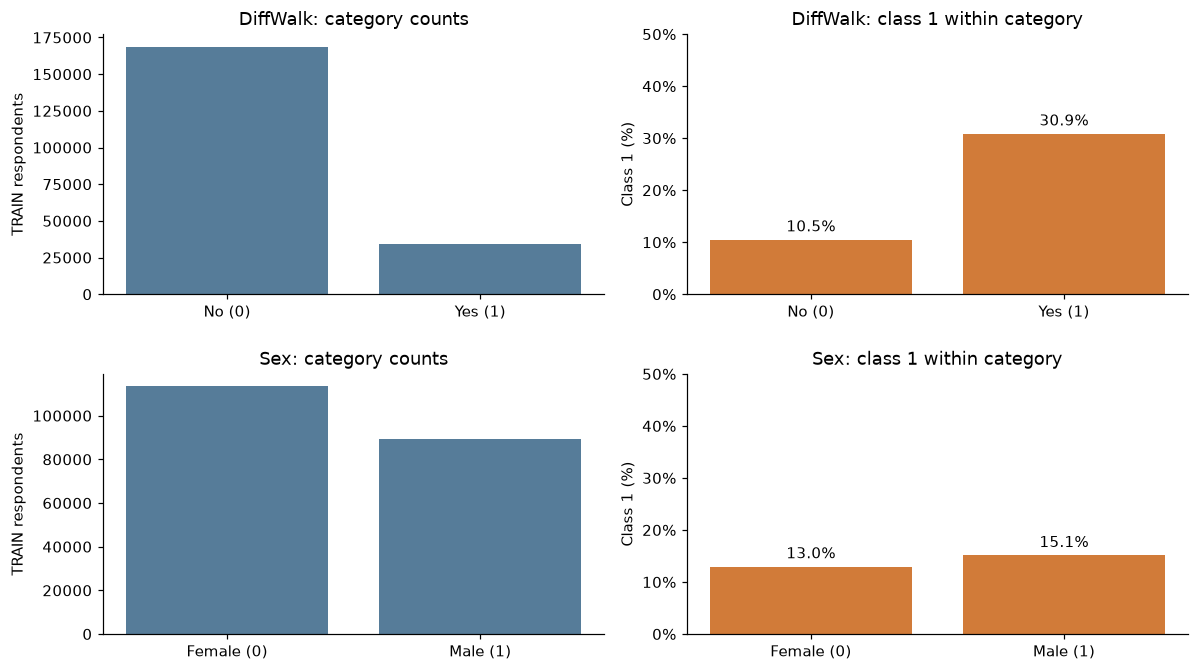

In [6]:
def category_table(feature):
    counts = pd.crosstab(train_eda[feature], train_eda[target]).reindex(columns=[0, 1], fill_value=0)
    result = pd.DataFrame({'Count': counts.sum(axis=1), 'Class 1 count': counts[1]})
    result['Category percent'] = 100 * result['Count'] / len(train_eda)
    result['Class 1 percent'] = 100 * result['Class 1 count'] / result['Count']
    result.index.name = 'Code'
    return result

category_tables = {feature: category_table(feature) for feature in binary_features + ordinal_features}
binary_summary = pd.concat({f: category_tables[f] for f in binary_features}, names=['Feature'])
binary_summary.to_csv(RESULTS / 'binary_summary.csv')
display(binary_summary.round(2))
for start in range(0, len(binary_features), 4):
    features = binary_features[start:start + 4]
    fig, axes = plt.subplots(len(features), 2, figsize=(11, 3.1 * len(features)), squeeze=False)
    for row, feature in enumerate(features):
        table = category_tables[feature]
        labels = ['Female (0)', 'Male (1)'] if feature == 'Sex' else ['No (0)', 'Yes (1)']
        axes[row, 0].bar(labels, table['Count'], color='#567c99')
        axes[row, 0].set(title=f'{feature}: category counts', ylabel='TRAIN respondents')
        bars = axes[row, 1].bar(labels, table['Class 1 percent'], color='#d17b39')
        axes[row, 1].bar_label(bars, fmt='%.1f%%', padding=3)
        axes[row, 1].set(title=f'{feature}: class 1 within category', ylabel='Class 1 (%)', ylim=(0, 50))
        axes[row, 1].yaxis.set_major_formatter(PercentFormatter(100))
    fig.tight_layout(h_pad=2)
    show_figure(fig, f'eda_binary_{start // 4 + 1}.png')

### 3.3 Ordered categorical features

**Question:** How do class-1 proportions change across ordered age, health, education,
and income categories?

Counts and proportions are displayed in the guide's category order with meaningful labels.
The plotted class-1 percentage is calculated within each category. Categories have unequal
sample sizes and the codes are not measured distances. We do not use a correlation ranking
of those codes as a feature-selection rule.

Count  Class 1 count  Category percent  Class 1 percent
Feature   Code                                                         
GenHlth   1     36262            912             17.87             2.52
          2     71133           5074             35.05             7.13
          3     60582          10790             29.85            17.81
          4     25347           7840             12.49            30.93
          5      9620           3661              4.74            38.06
Age       1      4493             64              2.21             1.42
          2      6073            111              2.99             1.83
          3      8881            254              4.38             2.86
          4     11048            471              5.44             4.26
          5     12944            850              6.38             6.57
          6     15932           1411              7.85             8.86
          7     21108           2483             10.40            11.76
          8     24777           3451             12.21            13.93
          9     26537           4541             13.08            17.11
          10    25679           5239             12.65            20.40
          11    18789           4139              9.26            22.03
          12    12725           2697              6.27            21.19
          13    13958           2566              6.88            18.38
Education 1       142             40              0.07            28.17
          2      3248            962              1.60            29.62
          3      7588           1830              3.74            24.12
          4     50242           8825             24.76            17.56
          5     55862           8251             27.53            14.77
          6     85862           8369             42.31             9.75
Income    1      7870           1908              3.88            24.24
          2      9458           2456              4.66            25.97
          3     12832           2862              6.32            22.30
          4     16145           3275              7.96            20.28
          5     20709           3614             10.20            17.45
          6     29189           4254             14.38            14.57
          7     34489           4181             16.99            12.12
          8     72252           5727             35.60             7.93

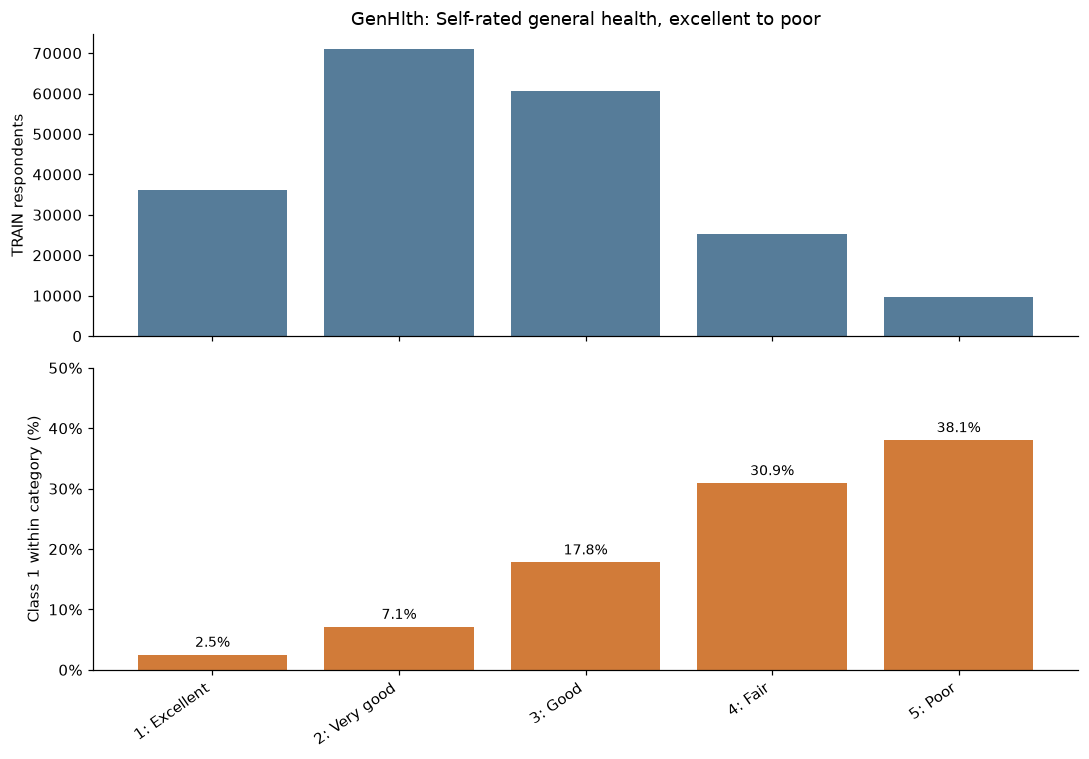

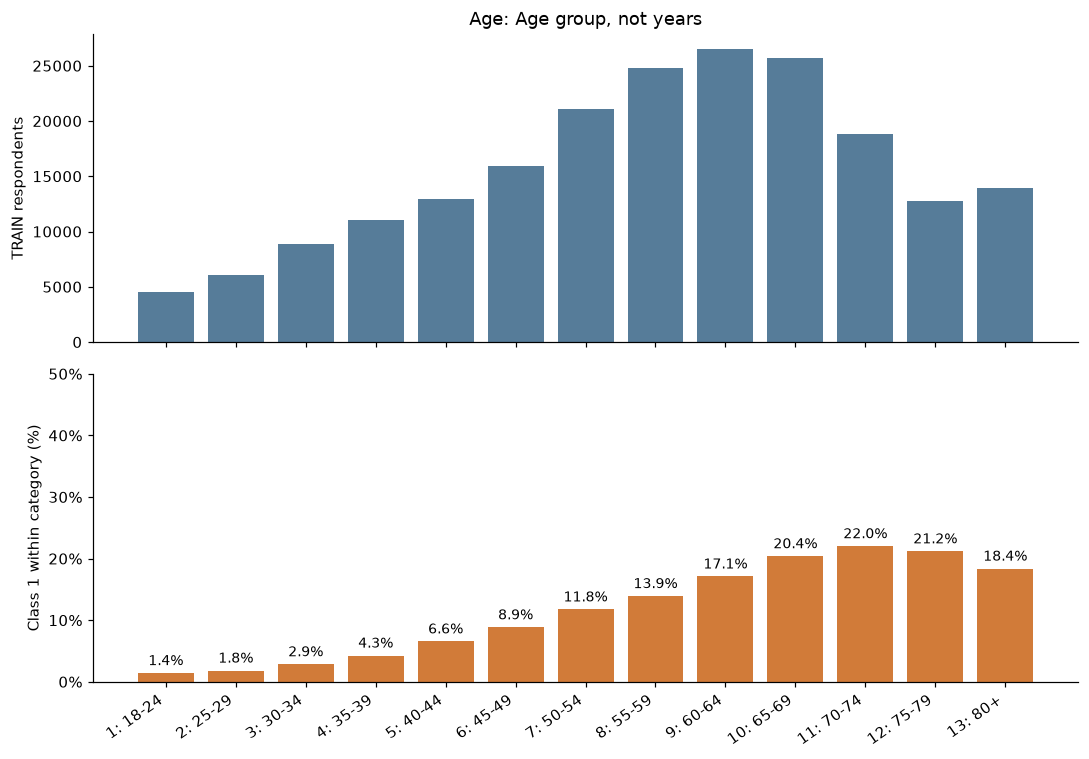

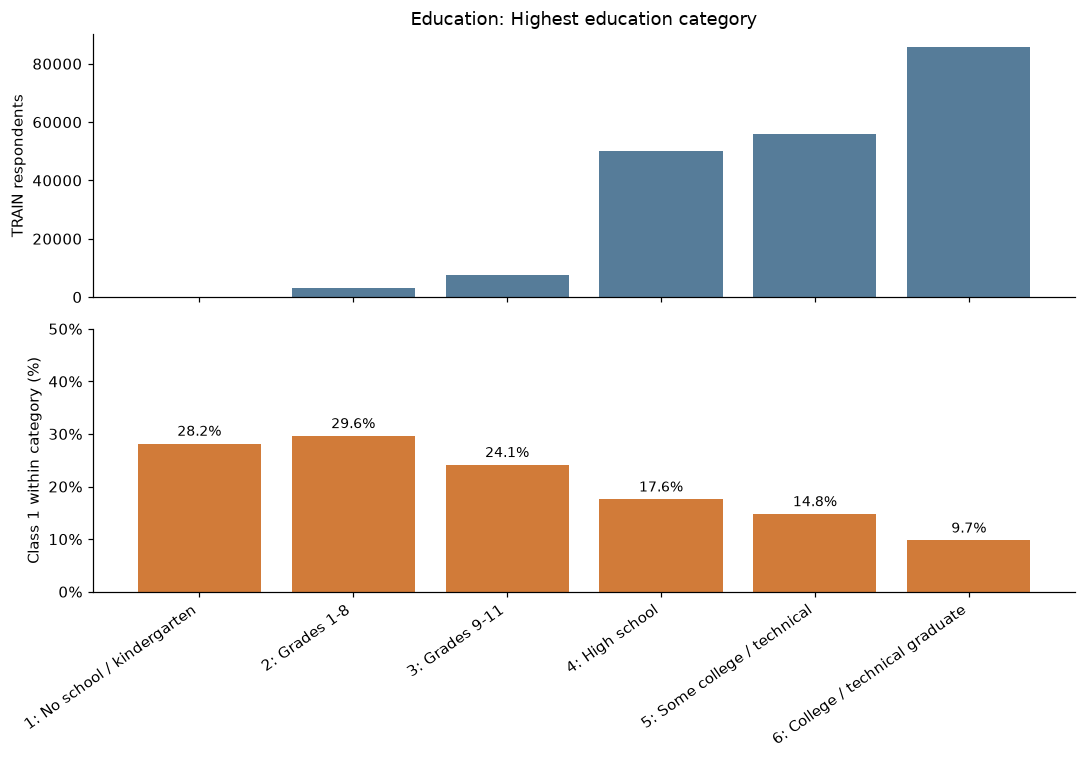

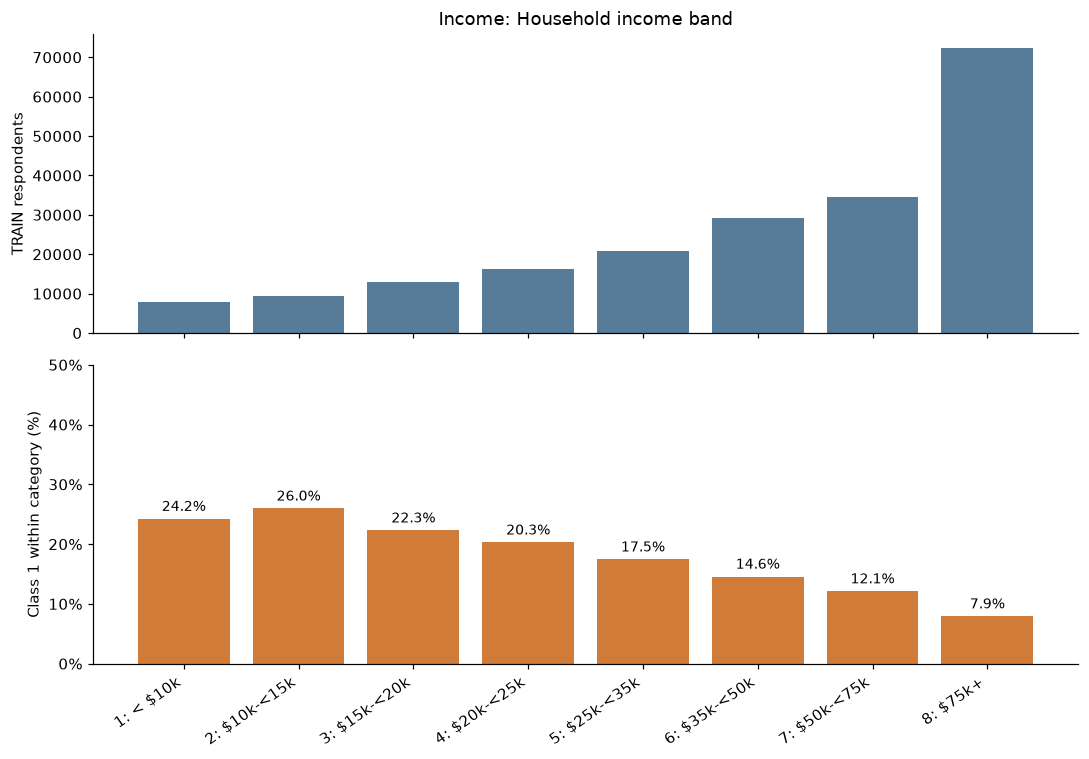

In [7]:
ordinal_summary = pd.concat({f: category_tables[f] for f in ordinal_features}, names=['Feature'])
ordinal_summary.to_csv(RESULTS / 'ordinal_summary.csv')
display(ordinal_summary.round(2))
for feature in ordinal_features:
    table = category_tables[feature]
    labels = [f'{int(code)}: {ordinal_labels[feature][int(code)-1]}' for code in table.index]
    positions = np.arange(len(labels))
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    axes[0].bar(positions, table['Count'], color='#567c99')
    axes[0].set(title=f'{feature}: {meanings[feature]}', ylabel='TRAIN respondents')
    bars = axes[1].bar(positions, table['Class 1 percent'], color='#d17b39')
    axes[1].bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)
    axes[1].set(ylabel='Class 1 within category (%)', ylim=(0, 50))
    axes[1].yaxis.set_major_formatter(PercentFormatter(100))
    axes[1].set_xticks(positions, labels, rotation=35, ha='right')
    fig.tight_layout()
    show_figure(fig, f'eda_{feature}.png')

coverage = feature_guide[['Feature', 'Type']].copy()
coverage['Distribution and target comparison'] = 'Completed in Section 3'
coverage.to_csv(RESULTS / 'eda_coverage.csv', index=False)
assert len(coverage) == 21

### 3.4 Five findings and their implications

The following discussion is generated from TRAIN summaries, so the displayed numbers
can be traced directly to the preceding tables. These are descriptive associations,
not causal estimates or fitted-model importance scores.

In [8]:
def rate(feature, category):
    return float(category_tables[feature].loc[category, 'Class 1 percent'])

bmi_medians = train_eda.groupby(target)['BMI'].median()
age_peak_code = int(category_tables['Age']['Class 1 percent'].idxmax())
findings = [
    ('BMI', f"Median BMI is {bmi_medians[0]:.0f} in class 0 and {bmi_medians[1]:.0f} in class 1. "
     'The distributions overlap, so the difference supports an association without giving a reliable single-value classification rule.'),
    ('High blood pressure', f"Class 1 accounts for {rate('HighBP', 0):.2f}% of respondents without high blood pressure "
     f"and {rate('HighBP', 1):.2f}% of those with it. The difference makes this a useful candidate predictor, "
     'but it may also reflect age or other shared characteristics.'),
    ('General health', f"The class-1 proportion is {rate('GenHlth', 1):.2f}% for excellent health "
     f"and {rate('GenHlth', 5):.2f}% for poor health. These self-reported categories relate strongly to the target. "
     'The data do not establish whether poor health precedes the condition or reflects its consequences.'),
    ('Age', f"The class-1 proportion is {rate('Age', 1):.2f}% at ages 18-24. It peaks at "
     f"{rate('Age', age_peak_code):.2f}% in the {ordinal_labels['Age'][age_peak_code-1]} group, "
     f"compared with {rate('Age', 13):.2f}% at 80+. Read the actual category pattern rather than assuming "
     'that each older group must have a higher proportion. Age is a grouped predictor, not an exact age.'),
    ('Heavy alcohol indicator', f"Class-1 proportions are {rate('HvyAlcoholConsump', 0):.2f}% for code 0 "
     f"and {rate('HvyAlcoholConsump', 1):.2f}% for code 1. This observed association cannot establish "
     'a protective effect: group composition, reporting differences, or behaviour following diagnosis could contribute.')]
display(Markdown('\n\n'.join(f'**{title}.** {body}' for title, body in findings)))
display(Markdown('**Decision:** retain all 21 predictors, represent each by its documented meaning, '
                 'and fit the prescribed model. None of these unadjusted comparisons justifies a causal claim or automatic feature deletion.'))

**BMI.** Median BMI is 27 in class 0 and 31 in class 1. The distributions overlap, so the difference supports an association without giving a reliable single-value classification rule.

**High blood pressure.** Class 1 accounts for 6.03% of respondents without high blood pressure and 24.46% of those with it. The difference makes this a useful candidate predictor, but it may also reflect age or other shared characteristics.

**General health.** The class-1 proportion is 2.52% for excellent health and 38.06% for poor health. These self-reported categories relate strongly to the target. The data do not establish whether poor health precedes the condition or reflects its consequences.

**Age.** The class-1 proportion is 1.42% at ages 18-24. It peaks at 22.03% in the 70-74 group, compared with 18.38% at 80+. Read the actual category pattern rather than assuming that each older group must have a higher proportion. Age is a grouped predictor, not an exact age.

**Heavy alcohol indicator.** Class-1 proportions are 14.41% for code 0 and 5.81% for code 1. This observed association cannot establish a protective effect: group composition, reporting differences, or behaviour following diagnosis could contribute.

**Decision:** retain all 21 predictors, represent each by its documented meaning, and fit the prescribed model. None of these unadjusted comparisons justifies a causal claim or automatic feature deletion.

## 4. Prepare features and define Logistic Regression

**Question:** How should the model receive each variable type?

`StandardScaler` handles BMI and the two genuine counts of days. Binary variables already
have a 0/1 representation and pass through unchanged. An explicit `OrdinalEncoder` follows
the documented order for GenHlth (1-5), Age (1-13), Education (1-6), and Income (1-8).
The encoding maps these to 0-based ordered codes; the original meanings remain unchanged.
There are no nominal multi-category predictors requiring one-hot encoding.

The ordinal representation follows the lecture example, but it gives successive category
steps equal spacing in the model's linear log-odds. That assumption may be restrictive,
especially for income bands of different widths and age's open-ended final category.

No imputation is needed because the verified file has no missing values. Defining the
pipeline specifies operations; it does not fit scaling statistics or model coefficients.
We use the default regularisation and no class weighting or resampling. This gives a clear
course-level baseline, not a claim that these choices are optimal.

In [9]:
ordinal_categories = [list(range(1, len(ordinal_labels[f]) + 1)) for f in ordinal_features]
preprocessor = ColumnTransformer([
    ('numerical', StandardScaler(), numerical_features),
    ('ordinal', OrdinalEncoder(categories=ordinal_categories), ordinal_features),
    ('binary', 'passthrough', binary_features)
], remainder='drop')
model = Pipeline([
    ('preprocess', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])
print('Pipeline defined; it has not been fitted.')

Pipeline defined; it has not been fitted.


## 5. Fit once using TRAIN

`fit()` learns scaling means and standard deviations from X_train and model parameters
from the prepared TRAIN features and y_train. Explicit ordinal category lists come from
the guide. TEST has no role in fitting. We check convergence rather than suppressing
a warning and assuming that training succeeded.

In [10]:
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter('always')
    model.fit(X_train, y_train)
for warning in fit_warnings:
    print(f'{warning.category.__name__}: {warning.message}')
assert not any(issubclass(w.category, ConvergenceWarning) for w in fit_warnings)
scaler = model.named_steps['preprocess'].named_transformers_['numerical']
np.testing.assert_allclose(scaler.mean_, X_train[numerical_features].mean().to_numpy())
print('Convergence iterations:', model.named_steps['classifier'].n_iter_)
print('Fit warnings:', len(fit_warnings))

Convergence iterations: [75]
Fit warnings: 0


## 6. Predict and evaluate on TEST

**Question:** Which respondents does the model classify correctly, and which errors does it make?

The fitted pipeline applies TRAIN transformations to X_test, then predicts. `predict()`
returns classes. `predict_proba()` returns a column per class; we verify that column 1
means the supplied positive class. We evaluate only now, without modifying the model.

For the always-class-0 reference, precision is undefined because there are no positive predictions. The table reports 0 by the explicit `zero_division=0` convention. Recall and F1 are zero because no positive cases are detected.

,Actual class,Probability of class 1,Predicted class
0,0,0.1542,0
1,1,0.2917,0
2,0,0.0199,0
3,0,0.0332,0
4,1,0.4812,0
5,0,0.1188,0
6,0,0.0287,0
7,0,0.0109,0
8,0,0.0529,0
9,0,0.1669,0


,Threshold 0.50
Accuracy,0.862070
Precision,0.516337
Recall,0.158721
F1,0.242805
TN,42616.000000
FP,1051.000000
FN,5947.000000
TP,1122.000000


,Rule,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Always predict class 0,0.8607,0.0000,0.0000,0.0000,43667,0,7069,0
1,Logistic Regression at 0.50,0.8621,0.5163,0.1587,0.2428,42616,1051,5947,1122


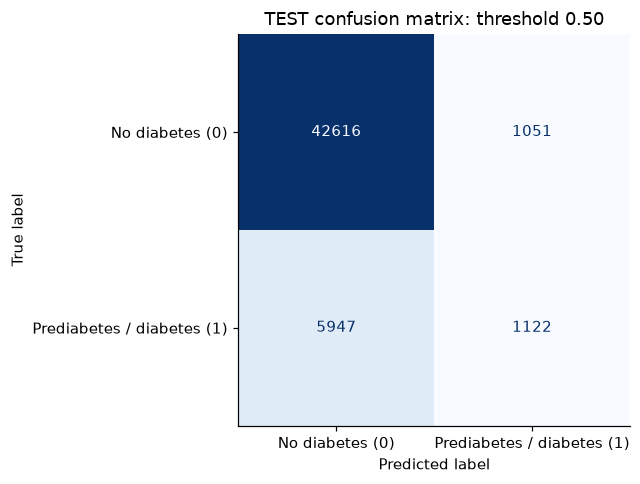

In [11]:
assert model.named_steps['classifier'].classes_.tolist() == [0, 1]
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]
assert np.isfinite(y_probability).all()
assert ((0 <= y_probability) & (y_probability <= 1)).all()
assert np.array_equal(y_pred, (y_probability >= .50).astype(int))
preview = pd.DataFrame({'Actual class': y_test.to_numpy()[:10],
                         'Probability of class 1': y_probability[:10],
                         'Predicted class': y_pred[:10]})
display(preview.round(4))

def evaluate_predictions(predictions):
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(y_test, predictions),
            'Precision': precision_score(y_test, predictions, zero_division=0),
            'Recall': recall_score(y_test, predictions, zero_division=0),
            'F1': f1_score(y_test, predictions, zero_division=0),
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

default_metrics = evaluate_predictions(y_pred)
display(pd.Series(default_metrics, name='Threshold 0.50').to_frame())
baseline = evaluate_predictions(np.zeros(len(y_test), dtype=int))
display(pd.DataFrame([{'Rule': 'Always predict class 0', **baseline},
                      {'Rule': 'Logistic Regression at 0.50', **default_metrics}]).round(4))
fig, ax = plt.subplots(figsize=(5.7, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['No diabetes (0)', 'Prediabetes / diabetes (1)'],
    colorbar=False, ax=ax, values_format='d', cmap='Blues')
ax.set_title('TEST confusion matrix: threshold 0.50')
fig.tight_layout()
show_figure(fig, 'confusion_matrix_050.png')

In [12]:
m = default_metrics
display(Markdown(
    f"At 0.50, there are **{m['FP']:,} false positives**: actual class-0 respondents predicted as class 1. "
    f"There are **{m['FN']:,} false negatives**: actual class-1 respondents predicted as class 0. "
    f"The model correctly identifies {m['TP']:,} class-1 respondents and {m['TN']:,} class-0 respondents.\n\n"
    f"**Accuracy is {m['Accuracy']:.2%}**: the share of all TEST respondents classified correctly. "
    f"**Precision is {m['Precision']:.2%}**: among positive predictions, the share actually in class 1. "
    f"**Recall is {m['Recall']:.2%}**: among actual class-1 respondents, the share found. "
    f"**F1 is {m['F1']:.4f}**, the harmonic mean of precision and recall.\n\n"
    f"Always predicting class 0 gives {baseline['Accuracy']:.2%} accuracy but zero recall. "
    'The fitted model therefore needs to be judged by its detection and errors, not just its overall accuracy. '
    'False positives could imply unnecessary follow-up; false negatives could mean missed opportunities for assessment. '
    'The dataset does not quantify those consequences, and the predictions are not confirmed diagnoses.'))

At 0.50, there are **1,051 false positives**: actual class-0 respondents predicted as class 1. There are **5,947 false negatives**: actual class-1 respondents predicted as class 0. The model correctly identifies 1,122 class-1 respondents and 42,616 class-0 respondents.

**Accuracy is 86.21%**: the share of all TEST respondents classified correctly. **Precision is 51.63%**: among positive predictions, the share actually in class 1. **Recall is 15.87%**: among actual class-1 respondents, the share found. **F1 is 0.2428**, the harmonic mean of precision and recall.

Always predicting class 0 gives 86.07% accuracy but zero recall. The fitted model therefore needs to be judged by its detection and errors, not just its overall accuracy. False positives could imply unnecessary follow-up; false negatives could mean missed opportunities for assessment. The dataset does not quantify those consequences, and the predictions are not confirmed diagnoses.

## 7. Compare thresholds 0.50 and 0.40

**Question:** What happens when we lower the probability needed for a class-1 decision?

We use the same fitted pipeline and the same probabilities for both prescribed thresholds.
The rule is `probability >= threshold`. We do not fit the model again or search TEST for
an optimal threshold. The two confusion matrices and the comparison table provide evidence.

,Threshold,Accuracy,Precision,Recall,F1,False positives,False negatives
0,0.5,0.8621,0.5163,0.1587,0.2428,1051,5947
1,0.4,0.8564,0.4731,0.2699,0.3437,2125,5161


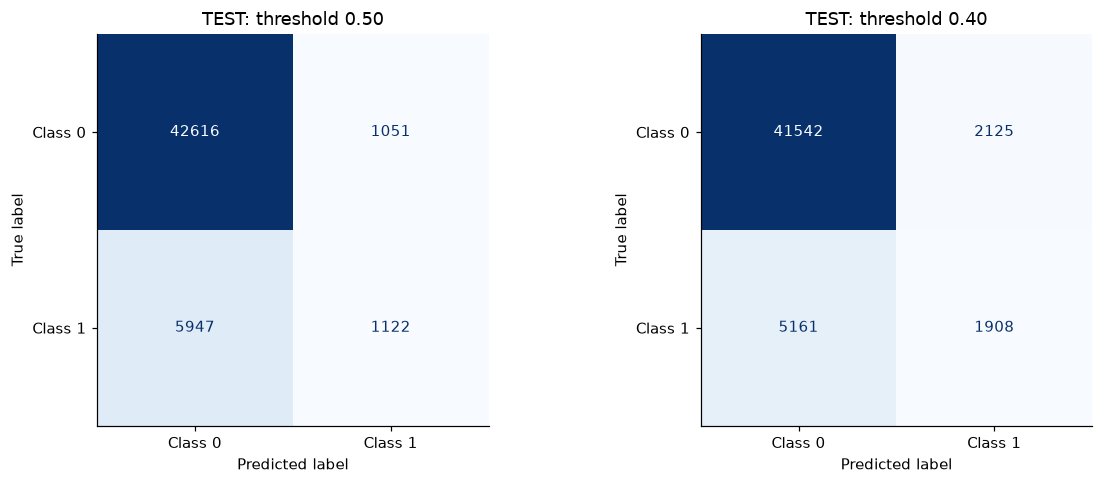

Lowering the threshold changes **1,860** predictions from class 0 to class 1. Of these respondents, 786 are actually class 1 and 1,074 are class 0. False negatives fall from 5,947 to 5,161, while false positives rise from 1,051 to 2,125.

Recall changes from 15.87% to 26.99%, precision from 51.63% to 47.31%, accuracy from 86.21% to 85.64%, and F1 from 0.2428 to 0.3437. These are the observed changes on this split, not assumptions about how every metric must behave.

The respondents, TRAIN scaling statistics, learned coefficients, and predicted probabilities do not change. Only the conversion from probability to class changes. The lower threshold finds more positive cases while producing more false alarms. Choosing a threshold for actual use would require evidence about error costs and external validation; this prescribed comparison does not provide that.

In [13]:
threshold_rows = []
for threshold in [.50, .40]:
    predictions = (y_probability >= threshold).astype(int)
    threshold_rows.append({'Threshold': threshold, **evaluate_predictions(predictions)})
threshold_results = pd.DataFrame(threshold_rows)
threshold_table = threshold_results.rename(columns={'FP': 'False positives', 'FN': 'False negatives'})[
    ['Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'False positives', 'False negatives']]
threshold_table.to_csv(RESULTS / 'threshold_comparison.csv', index=False)
threshold_results.to_csv(RESULTS / 'confusion_matrix_counts.csv', index=False)
display(threshold_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.5))
for ax, threshold in zip(axes, [.50, .40]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (y_probability >= threshold).astype(int), labels=[0, 1],
        display_labels=['Class 0', 'Class 1'], colorbar=False,
        ax=ax, values_format='d', cmap='Blues')
    ax.set_title(f'TEST: threshold {threshold:.2f}')
fig.tight_layout()
show_figure(fig, 'threshold_confusion_matrices.png')

a, b = threshold_rows
changed = (y_probability >= .40) & (y_probability < .50)
changed_positive = int(y_test.to_numpy()[changed].sum())
changed_negative = int(changed.sum() - changed_positive)
assert b['TP'] - a['TP'] == changed_positive
assert b['FP'] - a['FP'] == changed_negative
assert b['FN'] <= a['FN'] and b['FP'] >= a['FP']
display(Markdown(
    f"Lowering the threshold changes **{int(changed.sum()):,}** predictions from class 0 to class 1. "
    f"Of these respondents, {changed_positive:,} are actually class 1 and {changed_negative:,} are class 0. "
    f"False negatives fall from {a['FN']:,} to {b['FN']:,}, while false positives rise from {a['FP']:,} to {b['FP']:,}.\n\n"
    f"Recall changes from {a['Recall']:.2%} to {b['Recall']:.2%}, precision from {a['Precision']:.2%} to {b['Precision']:.2%}, "
    f"accuracy from {a['Accuracy']:.2%} to {b['Accuracy']:.2%}, and F1 from {a['F1']:.4f} to {b['F1']:.4f}. "
    'These are the observed changes on this split, not assumptions about how every metric must behave.\n\n'
    'The respondents, TRAIN scaling statistics, learned coefficients, and predicted probabilities do not change. '
    'Only the conversion from probability to class changes. The lower threshold finds more positive cases '
    'while producing more false alarms. Choosing a threshold for actual use would require evidence about '
    'error costs and external validation; this prescribed comparison does not provide that.'))

## 8. Conclusion and limitations

The survey features contain associations with the supplied binary outcome, but their
distributions overlap. Combining them in Logistic Regression supports some detection of
class 1 while leaving many false negatives at 0.50. Lowering the threshold trades fewer
missed positives for more false positives. Both thresholds need several metrics to be
understood; neither is validated for clinical use.

Limitations affect what we can conclude:

1. **Survey and timing limitations.** The guide describes survey-based variables. Reporting
   error and differences in who is represented can affect patterns. We lack a documented
   time sequence establishing which predictors preceded the outcome. These associations
   do not establish causation or prospective prediction of new disease.
2. **Combined outcome.** Class 1 merges prediabetes and diabetes. The analysis cannot
   evaluate detection of each condition separately, or disease severity.
3. **Model assumptions.** Logistic Regression is additive and linear in the represented
   features' log-odds. Ordered codes assume equal steps, despite unequal income intervals
   and grouped ages. Nonlinear patterns and interactions may not be captured well.
4. **Evaluation scope.** We use one random split of the supplied file, not external or
   temporal validation. No respondent identifiers are available to verify independence
   between respondents. Identical recorded rows remain as required. We have not assessed
   calibration, subgroup performance, or survey-weighted population estimates. The observed
   proportions and scores therefore describe this file and split, not a population guarantee.

## 9. Sources

- *Assignment 2: Diabetes Classification*, supplied assignment instructions and Canvas page.
- *Diabetes Classification: Understanding the Dataset*, supplied course guide. This is the
  authority used for target meanings, feature codes, and retaining identical rows.
- *Heart Disease Classification - Lecture Code* and *Lecture Classification Heart Disease v4*,
  supplied IE500618 teaching materials. Adapted preprocessing and threshold-comparison approach.
- Group's Assignment 1 notebook: https://github.com/MalkenBrutus/housing-price-prediction-group-26

The supplied materials are referenced by title. This repository does not redistribute the
course slides or archive. The CSV is the supplied assignment file; its checksum is recorded below.

In [14]:
summary = {
    'versions': versions, 'rows': len(df), 'predictors': len(all_features),
    'missing_cells': int(df.isna().sum().sum()), 'identical_rows_retained': int(df.duplicated().sum()),
    'class_counts': {str(k): int(v) for k, v in class_counts.items()},
    'train_rows': len(y_train), 'test_rows': len(y_test),
    'train_positive': int(y_train.sum()), 'test_positive': int(y_test.sum()),
    'baseline': baseline, 'threshold_results': threshold_rows,
    'findings': [{'title': title, 'text': body} for title, body in findings],
    'changed_predictions': int(changed.sum()), 'new_true_positives': changed_positive,
    'new_false_positives': changed_negative,
    'convergence_iterations': model.named_steps['classifier'].n_iter_.tolist(),
    'fit_warnings': [str(w.message) for w in fit_warnings],
    'csv_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'eda_scope': 'TRAIN only', 'random_state': 42, 'test_size': .20,
    'eda_feature_coverage': all_features}
(RESULTS / 'analysis_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('CSV SHA-256:', summary['csv_sha256'])
print('All 21 predictors covered. Tables and figures saved in results/ and figures/.')

CSV SHA-256: 19f367e3e3350768f0c144c5d73ee5b355f67a57eaaa86ca7bd8aec594d8b1d0
All 21 predictors covered. Tables and figures saved in results/ and figures/.
